# A substituent constant: the Hammett equation with fields

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/igbaskin/cmf-qsar/blob/main/docs/tutorials/07_a_substituent_constant.ipynb)

The earlier notebooks model what a molecule does to a protein or to a metal. This one models a
property of physical organic chemistry: the **Hammett constant** of a substituent. The constant
σ says how much a substituent X on a benzene ring changes the ionisation of benzoic acid. It has
two values, σ<sub>m</sub> for X in the meta position and σ<sub>p</sub> for X in the para position.
A positive value means that X withdraws electrons.

The series has two properties that make it a good lesson.

- **The frame is a rule.** Every molecule is X-C<sub>6</sub>H<sub>5</sub>, and the ring is put in
  the same place for all of them. So there is no alignment step, and nothing about the alignment
  can be tuned.
- **The chemistry of the answer is known.** A substituent acts through the bonds and through
  space (the inductive effect), and it also moves π electrons to or from the ortho and para
  carbons (the resonance effect). A meta position feels little of the second effect. So one can
  check whether the model has found this.

The data are 95 substituted benzenes with the constants of Hansch, Leo and Taft (Chem. Rev. 1991,
91, 165), in `examples/hammett`. The file used here also holds atomic charges from a quantum
calculation, so no quantum program is needed to run the notebook. One of the 95 records turns
out to be faulty, and the notebook shows how it was found and what it costs.

Running time: about a minute and a half.

In [1]:
# Run this cell first. On Google Colab it fetches the repository and installs the package;
# on a local checkout it only moves to the repository root, so that the example paths work.
import os, subprocess, sys

if "google.colab" in sys.modules:
    if not os.path.exists("cmf-qsar"):
        subprocess.run(["git", "clone", "-q", "https://github.com/igbaskin/cmf-qsar.git"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "./cmf-qsar", "py3Dmol"], check=True)
    os.chdir("cmf-qsar")
else:
    while not os.path.exists("pyproject.toml") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")
print("working in", os.getcwd())

working in C:\Users\baski\work\claude\cmf


## The data: 95 benzenes in one frame

`load_dataset` reads the file. Every substituent is stored as four records, and
`ensemble_by="name"` joins the records with one name into one molecule with four conformations.
The reason for the four records is given below.

Besides the two Hammett constants the file has the hydrophobic constant π of most of the
substituents. It is the change of the octanol-water log P that X causes, and it is used once
below, as a contrast.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from cmfqsar import load_dataset

ds = load_dataset("examples/hammett/hammett_qm_sym.sdf", activity_prop="sigma_m", ensemble_by="name")

def constants_of(some):
    return {t: np.array([float(m.GetProp(t)) if m.HasProp(t) else np.nan for m in some])
            for t in ("sigma_m", "sigma_p", "pi")}

whole = (list(ds.mols), list(ds.names), constants_of(ds.mols))       # all records of the file
print(len(whole[0]), "substituted benzenes,", whole[0][0].GetNumConformers(), "conformations each")

95 substituted benzenes, 4 conformations each


### One record that is not the molecule

Before any model, one record has to be looked at: the pentafluorosulfanyl group, SF<sub>5</sub>.
The cell prints the lengths of its five S-F bonds.

In [3]:
bad = whole[0][whole[1].index("SF5")]
xyz = bad.GetConformer().GetPositions()
sulfur = [a.GetIdx() for a in bad.GetAtoms() if a.GetSymbol() == "S"][0]
lengths = sorted(np.linalg.norm(xyz[a.GetIdx()] - xyz[sulfur]) for a in bad.GetAtoms() if a.GetSymbol() == "F")
print("S-F distances in the SF5 record, Å:", "  ".join("%.2f" % d for d in lengths))

keep = [i for i, n in enumerate(whole[1]) if n != "SF5"]
mols, names = [whole[0][i] for i in keep], [whole[1][i] for i in keep]
constant = constants_of(mols)
sm, sp = constant["sigma_m"], constant["sigma_p"]
print(len(mols), "substituents are used")
print("sigma_m from %.2f to %.2f, sigma_p from %.2f to %.2f" % (sm.min(), sm.max(), sp.min(), sp.max()))
print("pi is given for", int(np.isfinite(constant["pi"]).sum()), "of them")

S-F distances in the SF5 record, Å: 1.19  1.56  1.62  2.12  2.49
94 substituents are used
sigma_m from -0.23 to 1.20, sigma_p from -0.83 to 1.11
pi is given for 68 of them


A real S-F bond is about 1.6 Å long, and the five bonds of this group are nearly equal. The record
has distances from 1.2 to 2.5 Å. The force field that built the structures has no fitting
parameters for this group, and the structure it made is not the molecule. The quantum charges of
the file were computed on that structure, so they are not the charges of the molecule either.

The record is left out, and 94 substituents remain. It was not found by reading the file. It was
found with a plot of this notebook, in the section *One number for each constant*, where it lay
far from all other points. The section after that one shows what the record costs when it is
kept.

The two constants are related, and the way in which they differ is the chemistry of this notebook.
In the plot a substituent on the dotted line acts equally from both positions. A substituent far
below the line gives electrons by resonance, which reaches the para position and not the meta
position: the amino, hydroxy and methoxy groups, and fluorine.

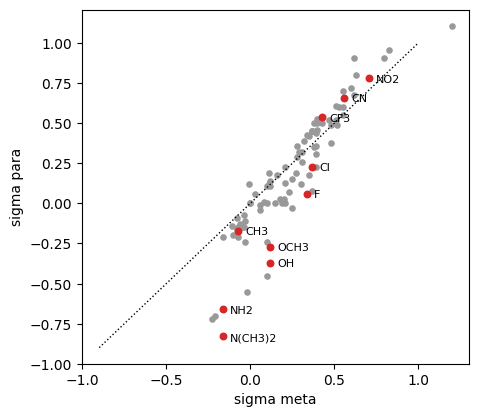

correlation of the two constants: 0.92


In [4]:
SHOWN = ["NO2", "CN", "CF3", "Cl", "F", "OCH3", "OH", "NH2", "N(CH3)2", "CH3"]
fig, ax = plt.subplots(figsize=(5.0, 4.6))
ax.scatter(sm, sp, s=14, color="0.6")
for s in SHOWN:
    i = names.index(s)
    ax.scatter(sm[i], sp[i], s=22, color="C3")
    ax.annotate(s, (sm[i], sp[i]), textcoords="offset points", xytext=(5, -3), fontsize=8)
ax.plot([-0.9, 1.0], [-0.9, 1.0], "k:", lw=1)
ax.set_xlabel("sigma meta"); ax.set_ylabel("sigma para"); plt.show()
print("correlation of the two constants: %.2f" % np.corrcoef(sm, sp)[0, 1])

## The frame

The centre of the ring is at the origin, the ring lies in the plane z = 0, and the carbon that
carries X (the ipso carbon) is on the +x axis. The plot shows the heavy atoms of all molecules
in that plane. The ring atoms of all molecules fall on the same six points, and the substituents
spread out to the right.

The ring has two mirror planes that keep this frame: y to −y and z to −z. A substituent that
leans to one side is as valid as its mirror image, and which image a conformer generator writes
is chance. So the file holds all four images of every molecule. The field of a molecule is then
the mean of the four, and it has the symmetry of the ring. This is why every map below is
symmetric about the x axis.

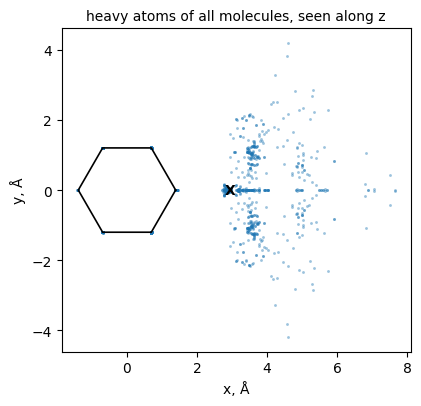

In [5]:
RING = 1.39 * np.array([[np.cos(t), np.sin(t)] for t in np.deg2rad(np.arange(0, 360, 60))])
RING_LABELS = ["ipso", "ortho", "meta", "para", "meta", "ortho"]

def draw_ring(ax, labels=True):
    ax.plot(*np.vstack([RING, RING[:1]]).T, color="k", lw=1.2)
    ax.text(2.95, 0, "X", ha="center", va="center", fontweight="bold")
    if labels:
        for (x, y), label in list(zip(RING, RING_LABELS))[1:4]:
            ax.text(1.5 * x, 1.5 * y + 0.1, label, ha="center", va="center", fontsize=8,
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75))
    ax.set_aspect("equal"); ax.set_xlabel("x, Å"); ax.set_ylabel("y, Å")

fig, ax = plt.subplots(figsize=(5.6, 4.2))
for m in mols:
    for conf in m.GetConformers():
        xyz = conf.GetPositions()
        heavy = [a.GetIdx() for a in m.GetAtoms() if a.GetAtomicNum() > 1]
        ax.scatter(xyz[heavy, 0], xyz[heavy, 1], s=4, color="C0", alpha=0.25, linewidths=0)
draw_ring(ax, labels=False)
ax.set_title("heavy atoms of all molecules, seen along z", fontsize=10); plt.show()

In [6]:
from rdkit import Chem

def view_overlay(some, size=(620, 380)):
    """A few molecules as they lie in the common frame."""
    try:
        import py3Dmol
    except ImportError:
        print("py3Dmol is not installed (pip install py3Dmol); the 3D view is skipped")
        return None
    v = py3Dmol.view(width=size[0], height=size[1])
    for k, m in enumerate(some):
        v.addModel(Chem.MolToMolBlock(m, confId=m.GetConformer(0).GetId()), "mol")
        v.setStyle({"model": k}, {"stick": {"radius": 0.10}})
    v.zoomTo()
    return v.show()

view_overlay([mols[names.index(s)] for s in ("NO2", "OCH3", "CF3", "N(CH3)2", "COCH3", "SO2CH3")])

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## A first model of σ<sub>m</sub>

The model is the one of the first notebook: the overlap kernel on the five default fields, with
kernel ridge regression. Two settings are chosen by cross-validation: the ridge λ, and the
attenuation factor α, which sets how fast the field of an atom falls off with distance. A larger
α is a narrower field. `conformers="ensemble"` tells the field set to use the mean field of the
four images.

The function `fit` is used for every model of this notebook. It scores a model on ten folds, five
times over with different folds, and keeps the mean of the five cross-validated predictions.

In [7]:
from types import SimpleNamespace
from cmfqsar import CMFModel, FieldSet
from cmfqsar.fields import AtomTable, build_fields
from cmfqsar.model import grid_search

ALPHAS = [0.3, 0.5, 0.8, 1.2, 2.0, 3.0]
LAMS = [1e-4, 1e-3, 1e-2, 0.1, 1.0, 10.0]
FIVE = ["electrostatic", "steric", "hydrophobic", "hba", "hbd"]
SEEDS = range(5)

def fit(target, fields=FIVE, charges=None, source=None, alphas=ALPHAS, seeds=SEEDS):
    """A model of one constant.  `charges` names a per-atom property of the file; a field of that
    property then takes the place of the electrostatic field, which uses Gasteiger charges.
    `source` is (molecules, names, constants); without it the 94 substituents are used."""
    some, some_names, values = source or (mols, names, constant)
    y = values[target]
    keep = np.flatnonzero(np.isfinite(y))
    physchem = [f for f in fields if not (charges and f == "electrostatic")]
    fs = FieldSet.create(physchem=physchem, atom_properties=[charges] if charges else [],
                         conformers="ensemble")
    table = AtomTable.from_molecules([build_fields(some[i], fs, name=some_names[i]) for i in keep])
    model = CMFModel(fieldset=fs, method="krr", fit_bias=True)
    search = grid_search(table, y[keep], model, alphas, lams=LAMS, folds=10, seed=0)
    q2, y_cv = [], []
    for seed in seeds:
        model.fit(table, y[keep], cv_folds=10, cv_seed=seed)
        q2.append(model.stats.q2); y_cv.append(np.array(model.stats.extra["y_cv"]))
    return SimpleNamespace(model=model, fs=fs, y=y[keep], q2=float(np.mean(q2)),
                           y_cv=np.mean(y_cv, axis=0), search=search)

gasteiger = {"sigma_m": fit("sigma_m")}
first = gasteiger["sigma_m"]
print(first.model.stats.summary())
print("mean q2 over the five sets of folds: %.2f" % first.q2)

Training set: n = 94
  r2 (fit)        = 0.959    RMSE (fit)  = 0.052
  q2 (10-fold CV)  = 0.763    RMSEcv      = 0.127
mean q2 over the five sets of folds: 0.74


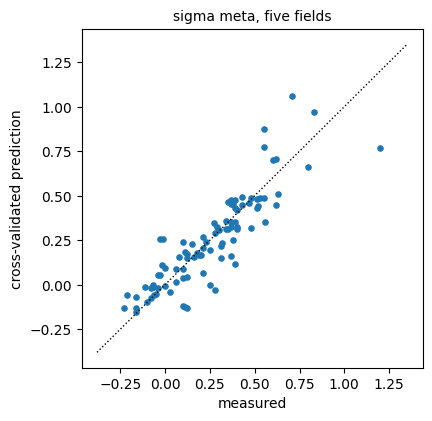

In [8]:
def cv_plot(ax, result, title):
    ax.scatter(result.y, result.y_cv, s=14)
    lo, hi = result.y.min() - 0.15, result.y.max() + 0.15
    ax.plot([lo, hi], [lo, hi], "k:", lw=1)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("measured"); ax.set_ylabel("cross-validated prediction")

fig, ax = plt.subplots(figsize=(4.4, 4.4))
cv_plot(ax, first, "sigma meta, five fields")
plt.show()

## Which field carries which constant

A field model can be asked which of its fields does the work: fit every field alone. The cell does
this for three of the fields and for the three constants. The expectation from chemistry is
clear. A Hammett constant is about electrons, so the electrostatic field should carry it. The
constant π is about hydrophobicity, so the hydrophobic field should carry it.

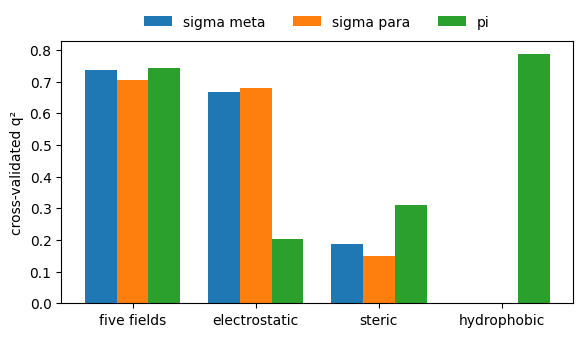

                  sigma_m    sigma_p         pi
five fields          0.74       0.70       0.74
electrostatic        0.67       0.68       0.20
steric               0.19       0.15       0.31
hydrophobic         -0.03      -0.01       0.79


In [9]:
by_field = {}
for target in ("sigma_m", "sigma_p", "pi"):
    for label, fields in (("five fields", FIVE), ("electrostatic", ["electrostatic"]),
                          ("steric", ["steric"]), ("hydrophobic", ["hydrophobic"])):
        if (target, label) == ("sigma_m", "five fields"):
            by_field[target, label] = first
        else:
            by_field[target, label] = fit(target, fields)
gasteiger["sigma_p"] = by_field["sigma_p", "five fields"]

labels = ["five fields", "electrostatic", "steric", "hydrophobic"]
fig, ax = plt.subplots(figsize=(6.6, 3.4))
for k, (target, name) in enumerate((("sigma_m", "sigma meta"), ("sigma_p", "sigma para"), ("pi", "pi"))):
    ax.bar(np.arange(4) + 0.26 * (k - 1), [max(by_field[target, l].q2, 0) for l in labels], 0.26, label=name)
ax.set_xticks(range(4)); ax.set_xticklabels(labels)
ax.set_ylabel("cross-validated q²")
ax.legend(frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0)); plt.show()
print("%-14s %10s %10s %10s" % ("", "sigma_m", "sigma_p", "pi"))
for l in labels:
    print("%-14s %10.2f %10.2f %10.2f" % (l, *(by_field[t, l].q2 for t in ("sigma_m", "sigma_p", "pi"))))

The table agrees with the expectation. The electrostatic field alone gives most of the score of
all five fields for both Hammett constants, and the hydrophobic field alone gives it for π. A bar
of zero height stands for a q² at or below zero.

The result for π is close to a tautology and should not be read as a discovery. The hydrophobic
field is built from the Crippen atom increments of log P, so it already holds a fragment estimate
of what π measures.

The scores of this notebook choose α and λ on the folds they are scored on, as the table of the
benchmark does (`benchmarks/results/hammett/table.md`). That table is computed on all 95 records,
so its numbers differ a little from these.

## The co-field: where the model reads

The prediction of this model is an integral of the field of the molecule against a weight
function in space, the **co-field**. A map of the co-field shows where the model reads.

One choice has to be made before a map is drawn. The cell prints the best cross-validated q² that
the search found for every attenuation factor α.

In [10]:
def score_by_alpha(results, heading):
    print(heading)
    print("    alpha  " + "".join("%7.1f" % a for a in ALPHAS))
    for target, r in results.items():
        best = [max(row["q2"] for row in r.search.table if row["alpha"] == a) for a in ALPHAS]
        print("    %-7s" % target + "".join("%7.2f" % q for q in best))

score_by_alpha(gasteiger, "best q2 at every alpha, five fields with Gasteiger charges")

best q2 at every alpha, five fields with Gasteiger charges
    alpha      0.3    0.5    0.8    1.2    2.0    3.0
    sigma_m   0.69   0.69   0.69   0.69   0.70   0.75
    sigma_p   0.68   0.69   0.68   0.66   0.64   0.65


The score changes little with α. So the score does not say how sharp the map should be,
and the reader has to choose. A wide field (small α) gives a smooth map. A narrow field (large α)
gives a map that can tell one ring carbon from the next. The question of this notebook is about
single ring carbons, so the maps below are drawn from models with α = 2. The scores above still
come from the search over all α.

`cofield_at_points` returns the co-field of one field at any list of points. The cell draws the
co-field of the electrostatic field in the plane of the ring, for σ<sub>m</sub> and for
σ<sub>p</sub>. Red means: positive charge at this place raises the predicted constant.

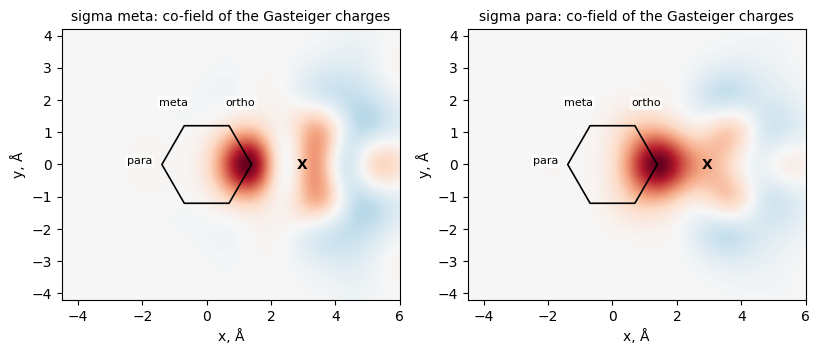

In [11]:
from cmfqsar.cofields import cofield_at_points

xs, ys = np.linspace(-4.5, 6.0, 141), np.linspace(-4.2, 4.2, 113)
GX, GY = np.meshgrid(xs, ys)
PLANE = np.column_stack([GX.ravel(), GY.ravel(), np.zeros(GX.size)])

def draw_cofields(charges, field, heading):
    """The co-field of one field in the plane of the ring, from models with alpha = 2."""
    fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.9))
    for ax, (target, name) in zip(axes, (("sigma_m", "sigma meta"), ("sigma_p", "sigma para"))):
        r = fit(target, charges=charges, alphas=[2.0], seeds=[0])
        v = cofield_at_points(r.model, r.fs.names.index(field), PLANE).reshape(GX.shape)
        lim = np.abs(v).max()
        ax.imshow(v, extent=[xs[0], xs[-1], ys[0], ys[-1]], origin="lower", cmap="RdBu_r",
                  vmin=-lim, vmax=lim)
        draw_ring(ax)
        ax.set_title("%s: co-field of %s" % (name, heading), fontsize=10)
    plt.show()

draw_cofields(None, "electrostatic", "the Gasteiger charges")

The two maps are nearly the same. Both models read one thing: positive charge at the ipso carbon
and on the first atom of X. That is a group that pulls electrons out of the ring through its
bond, the inductive effect. It is a fair description of σ<sub>m</sub>. For σ<sub>p</sub> it is not
enough, because the map has nothing at the para carbon.

The reason is in the charges and not in the model. Gasteiger charges come from the
electronegativity of the atoms along the bonds. They do not know about π electrons, so the ring
carbons of anisole and of nitrobenzene get nearly the same charges. A model cannot read from a
field what the field does not hold.

## Charges from a quantum calculation

A quantum calculation on the whole molecule gives charges that do hold the answer of the ring to
the substituent. The file has them as a property of every atom: the Hirshfeld charges
`q_hirshfeld`, computed with ORCA by `examples/orca_atom_properties.py`. `atom_properties` makes a
field of any such property. Here that field takes the place of the electrostatic field, and the
other four fields stay.

A difference between two scores on 94 molecules needs an interval. `paired_interval` draws the
molecules with replacement 2000 times and takes the difference of the two q² each time.

sigma_m: q2 0.74 with Gasteiger charges, 0.89 with Hirshfeld charges; difference +0.14 [+0.07, +0.24]
sigma_p: q2 0.70 with Gasteiger charges, 0.90 with Hirshfeld charges; difference +0.20 [+0.13, +0.29]
best q2 at every alpha, five fields with Hirshfeld charges
    alpha      0.3    0.5    0.8    1.2    2.0    3.0
    sigma_m   0.87   0.87   0.88   0.89   0.89   0.87
    sigma_p   0.90   0.89   0.87   0.86   0.86   0.85


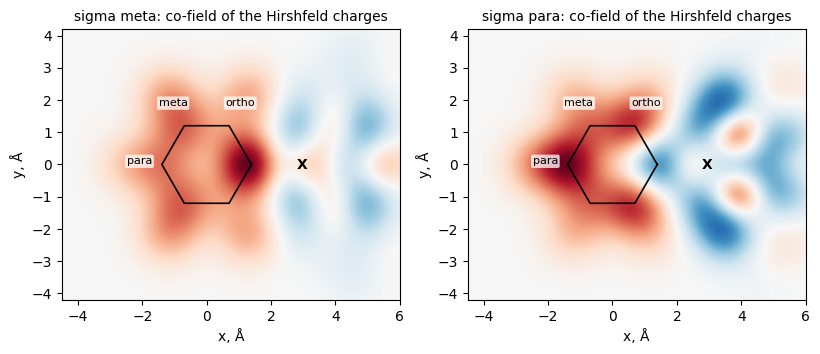

In [12]:
def q2_of(y, pred):
    return 1 - np.sum((pred - y) ** 2) / np.sum((y - y.mean()) ** 2)

def paired_interval(y, pred_a, pred_b, runs=2000, seed=0):
    """q2 of a minus q2 of b, with a 95 % interval from a bootstrap over the molecules."""
    rng = np.random.default_rng(seed)
    rows = rng.integers(0, len(y), (runs, len(y)))
    diffs = [q2_of(y[r], pred_a[r]) - q2_of(y[r], pred_b[r]) for r in rows]
    return (q2_of(y, pred_a) - q2_of(y, pred_b), *np.percentile(diffs, [2.5, 97.5]))

hirshfeld = {t: fit(t, charges="q_hirshfeld") for t in ("sigma_m", "sigma_p")}
for target in ("sigma_m", "sigma_p"):
    g, h = gasteiger[target], hirshfeld[target]
    print("%s: q2 %.2f with Gasteiger charges, %.2f with Hirshfeld charges; difference %+.2f [%+.2f, %+.2f]"
          % (target, g.q2, h.q2, *paired_interval(g.y, h.y_cv, g.y_cv)))
score_by_alpha(hirshfeld, "best q2 at every alpha, five fields with Hirshfeld charges")
draw_cofields("q_hirshfeld", "prop:q_hirshfeld", "the Hirshfeld charges")

Look at the maps first. They are no longer the same, and both now have weight on the ring
carbons that are far from X.

- **σ<sub>p</sub>:** the red lies at the para carbon and at the two ortho carbons, and the ipso
  carbon has none. These are the three carbons to which a substituent gives π electrons, or from
  which it takes them, by resonance.
- **σ<sub>m</sub>:** the red is strongest at the ipso carbon and weaker at the ortho and meta
  carbons. The para carbon has the least. This map does not single out one position as clearly.

Nobody told the model which carbon is para. It received 94 fields and 94 numbers.

Then look at the scores. Both go up with the quantum charges, and both intervals of the
difference exclude zero. So 94 substituents are enough to show the gain. The score also changes
little with α here, as it did with the Gasteiger charges.

## One number for each constant

The maps suggest a much simpler model. If a constant is read from the charge of a ring carbon,
then that charge alone may predict it: one number for a molecule, in a linear regression with one
coefficient. The cell tries every position of the ring for both constants, on folds that are
drawn in the same way as the folds of the field models. Then it compares the best number for each
constant with the field models.

q2 of a linear regression on the charge of one ring carbon
    carbon     sigma_m   sigma_p
    ipso         -0.02      0.10
    ortho         0.45      0.74
    meta          0.88      0.78
    para          0.60      0.87
sigma_m from the charge of the meta carbon: q2 0.88
    five fields with Gasteiger charges (q2 0.74) minus this number: -0.13 [-0.24, -0.06]
    five fields with Hirshfeld charges (q2 0.89) minus this number: +0.01 [-0.03, +0.04]
sigma_p from the charge of the para carbon: q2 0.87
    five fields with Gasteiger charges (q2 0.70) minus this number: -0.16 [-0.26, -0.07]


    five fields with Hirshfeld charges (q2 0.90) minus this number: +0.04 [-0.01, +0.10]


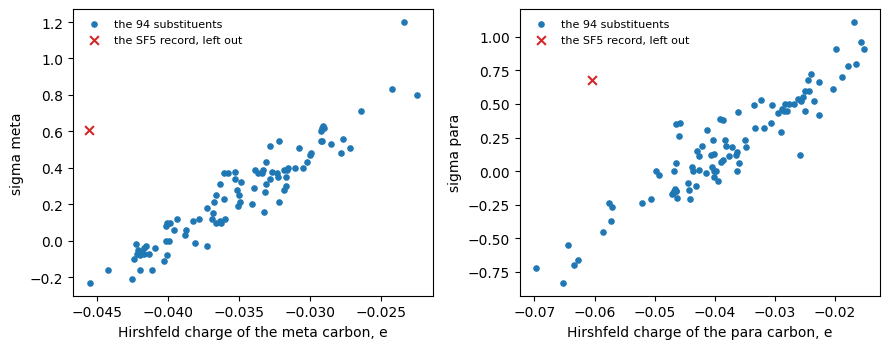

In [13]:
def ring_carbon_charge(mol, position):
    """Mean Hirshfeld charge of the ring carbons at one position.  The six ring carbons are the
    first six atoms; the angle about the ring centre is 0 at the ipso carbon and 180 at para."""
    xyz = mol.GetConformer().GetPositions()[:6]
    angle = np.abs(np.degrees(np.arctan2(xyz[:, 1], xyz[:, 0])))
    low, high = {"ipso": (-1, 30), "ortho": (30, 90), "meta": (90, 150), "para": (150, 181)}[position]
    q = np.array([mol.GetAtomWithIdx(i).GetDoubleProp("q_hirshfeld") for i in range(6)])
    return q[(angle > low) & (angle <= high)].mean()

def regression_cv(x, y):
    """Cross-validated prediction of a linear regression of y on x, and its mean q2."""
    X = np.column_stack([np.ones(len(y)), x])
    preds = []
    for seed in SEEDS:
        order = np.random.RandomState(seed).permutation(len(y))
        pred = np.zeros(len(y))
        for k in range(10):
            test = order[k::10]
            rest = np.setdiff1d(order, test)
            pred[test] = X[test] @ np.linalg.lstsq(X[rest], y[rest], rcond=None)[0]
        preds.append(pred)
    return np.mean(preds, axis=0), float(np.mean([q2_of(y, p) for p in preds]))

print("q2 of a linear regression on the charge of one ring carbon")
print("    %-8s %9s %9s" % ("carbon", "sigma_m", "sigma_p"))
for where in ("ipso", "ortho", "meta", "para"):
    x = np.array([ring_carbon_charge(m, where) for m in mols])
    print("    %-8s %9.2f %9.2f" % (where, regression_cv(x, sm)[1], regression_cv(x, sp)[1]))

POSITION = {"sigma_m": "meta", "sigma_p": "para"}
charge = {t: np.array([ring_carbon_charge(m, POSITION[t]) for m in mols]) for t in POSITION}
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.6))
for ax, target in zip(axes, POSITION):
    y = constant[target]
    pred, q2 = regression_cv(charge[target], y)
    ax.scatter(charge[target], y, s=14, label="the 94 substituents")
    i = whole[1].index("SF5")                             # the record that was left out
    ax.scatter(ring_carbon_charge(whole[0][i], POSITION[target]), whole[2][target][i], s=40,
               marker="x", color="C3", label="the SF5 record, left out")
    ax.set_xlabel("Hirshfeld charge of the %s carbon, e" % POSITION[target])
    ax.set_ylabel("sigma " + POSITION[target]); ax.legend(frameon=False, fontsize=8)
    print("%s from the charge of the %s carbon: q2 %.2f" % (target, POSITION[target], q2))
    for name, r in (("Gasteiger", gasteiger[target]), ("Hirshfeld", hirshfeld[target])):
        print("    five fields with %s charges (q2 %.2f) minus this number: %+.2f [%+.2f, %+.2f]"
              % (name, r.q2, *paired_interval(y, r.y_cv, pred)))
plt.tight_layout(); plt.show()

The first table is the chemistry of the Hammett constants with no model in between.
σ<sub>m</sub> is predicted best by the charge of the meta carbon and σ<sub>p</sub> by the charge
of the para carbon. The ortho carbon predicts σ<sub>p</sub> much better than σ<sub>m</sub>, as
resonance says it should. The ipso carbon predicts neither.

One charge predicts each constant as well as the field model with the quantum charges does: the
intervals of those two differences contain zero. Both are clearly ahead of the field model with
Gasteiger charges.

This is the comparison to make before a field model is given credit. Read it in three parts.

**What the field model did.** For σ<sub>p</sub> it found the place. Its map put the weight at the
para and ortho carbons, without being told. A chemist who did not know the resonance effect could
have read it from that map.

**What the map did not show.** The map of σ<sub>m</sub> is strongest at the ipso carbon, and the
charge of the ipso carbon alone predicts nothing. This is no contradiction. A co-field is the
weight of a place in a model that reads all places together. It is not the correlation of that
place alone with the answer. The table of single carbons was needed to name the meta carbon.

**What the field model did not do.** It does not predict better than one number. On this series
the fields add nothing that is resolved to the charge of one carbon atom. So a reader who has the
quantum charges can use the one number and leave the fields out.

The red cross in each plot is the SF<sub>5</sub> record that was left out at the start. This is
the plot in which it was found.

## What one faulty record costs

The cell fits the models again on all 95 records, with the SF<sub>5</sub> record among them.

In [14]:
print("%-46s %12s %12s" % ("cross-validated q2", "94 records", "all 95"))
for target in POSITION:
    with_it = fit(target, charges="q_hirshfeld", source=whole)
    print("%-46s %12.2f %12.2f" % (target + ", five fields with Hirshfeld charges",
                                    hirshfeld[target].q2, with_it.q2))
    x_all = np.array([ring_carbon_charge(m, POSITION[target]) for m in whole[0]])
    print("%-46s %12.2f %12.2f" % (target + ", charge of the %s carbon" % POSITION[target],
                                    regression_cv(charge[target], constant[target])[1],
                                    regression_cv(x_all, whole[2][target])[1]))

cross-validated q2                               94 records       all 95


sigma_m, five fields with Hirshfeld charges            0.89         0.78
sigma_m, charge of the meta carbon                     0.88         0.76


sigma_p, five fields with Hirshfeld charges            0.90         0.73
sigma_p, charge of the para carbon                     0.87         0.76


One record of 95 lowers every score in the table by more than 0.1. A q² is built from squared
errors, so one point that lies far from the others weighs as much as many ordinary ones.

No score showed that this record was faulty. A score only gets lower, and a lower score has many
possible causes. The plot of one number against the constant showed it at once. So look at the
points before the scores, and look at the structure of every point that lies apart.

## The substituents that give electrons by resonance

The cross-validated predictions of the substituents marked in the first plot. For each constant
the three columns are the measured value, the prediction with Gasteiger charges and the prediction
with Hirshfeld charges.

In [15]:
print("%-9s | %8s %10s %10s | %8s %10s %10s" % ("", "sigma_m", "Gasteiger", "Hirshfeld",
                                               "sigma_p", "Gasteiger", "Hirshfeld"))
for s in SHOWN:
    i = names.index(s)
    print("%-9s | %8.2f %10.2f %10.2f | %8.2f %10.2f %10.2f" % (
        s, sm[i], gasteiger["sigma_m"].y_cv[i], hirshfeld["sigma_m"].y_cv[i],
        sp[i], gasteiger["sigma_p"].y_cv[i], hirshfeld["sigma_p"].y_cv[i]))

          |  sigma_m  Gasteiger  Hirshfeld |  sigma_p  Gasteiger  Hirshfeld
NO2       |     0.71       1.06       0.76 |     0.78       1.27       0.92
CN        |     0.56       0.35       0.47 |     0.66       0.39       0.71
CF3       |     0.43       0.49       0.40 |     0.54       0.67       0.54
Cl        |     0.37       0.35       0.32 |     0.23       0.20       0.20
F         |     0.34       0.32       0.24 |     0.06       0.23       0.18
OCH3      |     0.12       0.04       0.00 |    -0.27      -0.19      -0.24
OH        |     0.12      -0.13      -0.04 |    -0.37      -0.44      -0.38
NH2       |    -0.16      -0.13      -0.16 |    -0.66      -0.32      -0.46
N(CH3)2   |    -0.16      -0.07      -0.12 |    -0.83      -0.30      -0.50
CH3       |    -0.07      -0.00      -0.02 |    -0.17      -0.06      -0.20


Read the lines of the two amino groups first. Their measured σ<sub>p</sub> is strongly negative.
With Gasteiger charges the model predicts half of that or less. With Hirshfeld charges it comes
closer, and still not all the way. The nitro group is predicted far too high with Gasteiger
charges and much closer with Hirshfeld charges.

Then read the line of fluorine. Its measured σ<sub>p</sub> is close to zero, because the pull
through the bond and the gift of π electrons nearly cancel. Both models predict a clearly
positive value. A table like this one shows where a model fails; a single q² does not.

## A substituent of your own

A substituent that is not in the file has to be put into the same frame. The script that built
the data set does this: `build` makes X-C<sub>6</sub>H<sub>5</sub> from the SMILES of X, written as
it follows the ring atom, and `symmetry_images` writes the four images. The model with Gasteiger
charges is used, because it needs nothing but the structure. `predict_with_sd` returns a standard
deviation beside every prediction; the third notebook explains what it is for.

The three substituents below are not in the file. No measured values are given here: look them
up in the review named at the top before a prediction is trusted.

In [16]:
import sys
sys.path.insert(0, "examples")
from make_hammett_examples import build, symmetry_images
from cmfqsar.conformers import group_conformers

def substituent_table(fragment, label, fs):
    images = symmetry_images(build(fragment))            # four images of X-C6H5 in the frame
    joined, _, _ = group_conformers(images, [label] * len(images))
    return AtomTable.from_molecules([build_fields(joined[0], fs, name=label)])

print("%-12s %18s %18s" % ("", "sigma_m", "sigma_p"))
for fragment, label in (("OC(F)F", "OCHF2"), ("C(=O)N(C)C", "CON(CH3)2"), ("S(=O)(=O)N(C)C", "SO2N(CH3)2")):
    line = "%-12s" % label
    for target in ("sigma_m", "sigma_p"):
        r = gasteiger[target]
        value, sd = r.model.predict_with_sd(substituent_table(fragment, label, r.fs))
        line += "      %+.2f +- %.2f" % (value[0], sd[0])
    print(line)

                        sigma_m            sigma_p
OCHF2             +0.35 +- 0.10      +0.15 +- 0.19


CON(CH3)2         +0.28 +- 0.11      +0.33 +- 0.19


SO2N(CH3)2        +0.70 +- 0.12      +0.64 +- 0.20


## The same model from the command line

```
cmf build examples/hammett/hammett_sym.sdf --activity sigma_m --ensemble-by name --conformations ensemble --save sigma_m.cmf
cmf build examples/hammett/hammett_qm_sym.sdf --activity sigma_m --ensemble-by name --conformations ensemble --fields steric,hydrophobic,hba,hbd,prop:q_hirshfeld --save sigma_m_qm.cmf
```

The first line is the model with Gasteiger charges and the second the model with the Hirshfeld
charges of the file. For a series of your own, `examples/orca_atom_properties.py` writes such
charges into an SD file; it needs the ORCA program.

Where to read further in the manual: *A co-field around one atom: the local alignment* shows the
co-fields of both constants in two planes, *Reading a few places instead of all of them* reads
fields at named points of this frame, and *A vibrational band as the local target* models the
carbonyl band of the benzoic acids with these substituents and compares it with a linear
regression on the Hammett constant.